<a href="https://colab.research.google.com/github/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/blob/main/ProyectoFinal_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Proyecto Final

Integrantes:

271758 – Kevin Angel Quiñonez Dominguez

271760 – Juan Carlos Rivera Córdova

271770 – Gerardo Isidoro Reyes
<br/><br/>

A continuación, se utilizarán Python y las bibliotecas de análisis de datos pertinentes para responder las siguientes preguntas de investigación:
<br/><br/>

1. ¿Se observa algún cambio estructural o quiebre de tendencia en la serie temporal después de 2017, coincidiendo con la promulgación de la Ley General en Materia de Desaparición Forzada de Personas?
2. ¿Existe alguna relación o patrón estacional entre mes del año (ej. periodos vacacionales, o trimestres específicos) y el incremento repentino de registros?
3. ¿Qué grupo demográfico (male o female) presentó una mayor tasa de incremento porcentual acumulado entre 2015 y 2025?
4. ¿Cómo ha evolucionado el número de casos a través de los años?
5. ¿Qué entidades concentran más casos y cómo se distribuyen según condición?
6. ¿Cómo se relacionan sexo y condición, considerando las entidad?

<br/>

Colab URL: https://colab.research.google.com/drive/1mWKZ7OiW7gbOWALpuV7ZTJb-nWhZal7o?usp=sharing

DataSets en Github:

- https://raw.githubusercontent.com/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/refs/heads/main/rnpdno_disappeared_not_located.csv
- https://raw.githubusercontent.com/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/refs/heads/main/rnpdno_located_alive.csv
- https://raw.githubusercontent.com/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/refs/heads/main/rnpdno_located_dead.csv

**Importacion de bibliotecas, carga y almacenamiento local de conjuntos de datos desde repositorio remoto**

Gestionamos la importación de las tres librerías base (matplotlib, pandas, seaborn) e implementa un mecanismo de descarga y lectura automatizada para las fuentes de datos del proyecto desde GitHub.

Realiza las siguientes etapas clave:

1. Gestión de Entorno: Importa los módulos necesarios para la adquisición de datos (os, urllib.request), manipulación de tablas (pandas) y posterior visualización (matplotlib, seaborn).

2. Descarga Eficiente (Caché Local): Verifica la existencia local de cada uno de los tres archivos CSV (rnpdno_disappeared_not_located.csv, rnpdno_located_alive.csv y rnpdno_located_dead.csv) mediante os.path.exists(), descargándolos vía HTTP solo si no han sido recuperados previamente.

3. Carga en Memoria: Instancia y estructura los datos en tres DataFrames independientes (df_dnl, df_la y df_ld) listos para sus etapas posteriores de transformación y análisis.

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
import urllib.request

# Cargamos el archivo rnpdno_disappeared_not_located.csv para crear el DataFrame df_dnl
url_dnl = "https://raw.githubusercontent.com/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/refs/heads/main/rnpdno_disappeared_not_located.csv"
archivo_dnl = "rnpdno_disappeared_not_located.csv"
if not os.path.exists(archivo_dnl):
    urllib.request.urlretrieve(url_dnl, archivo_dnl)
df_dnl = pd.read_csv(archivo_dnl, sep=',')

# Cargamos el archivo rnpdno_located_alive.csv para crear el DataFrame df_la
url_la = "https://raw.githubusercontent.com/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/refs/heads/main/rnpdno_located_alive.csv"
archivo_la = "rnpdno_located_alive.csv"
if not os.path.exists(archivo_la):
    urllib.request.urlretrieve(url_la, archivo_la)
df_la = pd.read_csv(archivo_la, sep=",")

# Cargamos el archivo rnpdno_located_dead.csv para crear el DataFrame df_ld
url_ld = "https://raw.githubusercontent.com/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/refs/heads/main/rnpdno_located_dead.csv"
archivo_ld = "rnpdno_located_dead.csv"
if not os.path.exists(archivo_ld):
    urllib.request.urlretrieve(url_ld, archivo_ld)
df_ld = pd.read_csv(archivo_ld, sep=",")


**Integración y consolidación de conjuntos de datos de personas desaparecidas y localizadas**

Se procesan y unifican tres fuentes independientes de datos (df_dnl — desaparecidas no localizadas, df_la — localizadas con vida y df_ld — localizadas sin vida) a nivel municipal y mensual.

Realiza las siguientes etapas clave:

1. Estandarización: Elimina redundancias (status_id) y añade sufijos distintivos (_dnl, _la, _ld) a las métricas cuantitativas (male, female, undefined, total).

2. Unificación: Aplica un Full Outer Join mediante las dimensiones geográficas y temporales (cvegeo, state, municipality, year, month) para preservar todos los registros.

3. Limpieza e Imputación: Trata los valores nulos resultantes del cruce asignándoles 0 y formateándolos como números enteros (int).

4. Agregación Global: Construye columnas consolidadas por sexo (male_total, female_total, undefined_total, total_total) sumando la métrica a través de las tres condiciones.

In [21]:
# Definir las columnas que sirven como llave para alinear los registros
llaves = [
    'cvegeo',
    'cve_estado',
    'state',
    'cve_mun',
    'municipality',
    'year',
    'month',
]

# Eliminar 'status_id' de cada DataFrame
df_dnl = df_dnl.drop(columns=['status_id'], errors='ignore')
df_la = df_la.drop(columns=['status_id'], errors='ignore')
df_ld = df_ld.drop(columns=['status_id'], errors='ignore')

# Columnas cuantitativas que se usaran para agregar el sufijo correspondiente
cols_metrica = ['male', 'female', 'undefined', 'total']

# corresponde a rnpdno_disappeared_not_located.csv
df_dnl = df_dnl.rename(
    columns={col: f'{col}_dnl' for col in cols_metrica}
)

# corresponde a rnpdno_located_alive.csv
df_la = df_la.rename(
    columns={col: f'{col}_la' for col in cols_metrica}
)

# Corresponde a rnpdno_located_dead.csv
df_ld = df_ld.rename(
    columns={col: f'{col}_ld' for col in cols_metrica}
)

# Unimos los 3 DataFrames mediante un OUTER JOIN usando las llaves comunes
# (Usamos outer join para asegurar que no se pierdan municipios/meses que existan en uno pero no en otro)
df = df_dnl.merge(df_la, on=llaves, how='outer').merge(
    df_ld, on=llaves, how='outer'
)

# Rellenamos con 0 los valores nulos creados en combinaciones donde no existían registros
cols_cuantitativas = [
    c
    for c in df.columns
    if any(c.endswith(suf) for suf in ['_dnl', '_la', '_ld'])
]

# Si alguna columna contiene na despues de haberla agregado al df se llena con 0 para consistencia de los datos
df[cols_cuantitativas] = df[cols_cuantitativas].fillna(0).astype(int)

# Creamos 4 columnas para almacenar los totales de cada rubro
df['male_total'] = df['male_dnl'] + df['male_la'] + df['male_ld']
df['female_total'] = df['female_dnl'] + df['female_la'] + df['female_ld']
df['undefined_total'] = df['undefined_dnl'] + df['undefined_la'] + df['undefined_ld']
df['total_total'] = df['total_dnl'] + df['total_la'] + df['total_ld']

df

,cvegeo,cve_estado,state,cve_mun,municipality,male_dnl,female_dnl,undefined_dnl,total_dnl,year,...,undefined_la,total_la,male_ld,female_ld,undefined_ld,total_ld,male_total,female_total,undefined_total,total_total
0,1001,1,aguascalientes,1,aguascalientes,1,0,0,1,2015,...,0,38,1,0,0,1,19,21,0,40
1,1001,1,aguascalientes,1,aguascalientes,1,2,0,3,2015,...,0,18,0,0,0,0,7,14,0,21
2,1001,1,aguascalientes,1,aguascalientes,1,0,0,1,2015,...,0,34,0,0,0,0,12,23,0,35
3,1001,1,aguascalientes,1,aguascalientes,0,1,0,1,2015,...,0,43,1,0,0,1,17,28,0,45
4,1001,1,aguascalientes,1,aguascalientes,0,1,0,1,2015,...,0,33,1,0,0,1,11,24,0,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57367,99998,99,unknown,999,se desconoce,0,0,0,0,2024,...,0,1,0,0,0,0,1,0,0,1
57368,99998,99,unknown,999,se desconoce,1,0,0,1,2025,...,0,0,0,0,0,0,1,0,0,1
57369,99998,99,unknown,999,se desconoce,0,1,0,1,2025,...,0,0,0,0,0,0,0,1,0,1
57370,99999,99,unresolved,999,ocampo,1,0,0,1,2025,...,0,0,0,0,0,0,1,0,0,1


**Transformación y categorización de variables temporales**

Se estandariza la representación del tiempo en el DataFrame consolidado para facilitar su visualización y optimizar el procesamiento.

Realiza las siguientes etapas clave:

1. Mapeo Textual de Meses: Construye un diccionario de equivalencias (meses_mapping) para convertir las claves numéricas de los meses (1 al 12) a sus abreviaturas en español (Ene, Feb, etc.).

2. Generación y Categorización Ordinal de month_name: Asigna los nombres de los meses y los define explícitamente como una variable categórica ordenada (pd.Categorical), garantizando que gráficas y tablas dinámicas mantengan la secuencia natural de enero a diciembre sin recurrir al orden alfabético.

3. Optimización de Tipos de Datos: Convierte la columna numérica original month al tipo categórico de Pandas (category), optimizando el uso de memoria y garantizando un ordenamiento lógico consistente durante el análisis.

In [22]:
# Definimos el mappeo para número a nombre del mes, para posteriormente agregar una columna con ese valor
meses_mapping = {
    1: 'Ene',
    2: 'Feb',
    3: 'Mar',
    4: 'Abr',
    5: 'May',
    6: 'Jun',
    7: 'Jul',
    8: 'Ago',
    9: 'Sep',
    10: 'Oct',
    11: 'Nov',
    12: 'Dic',
}

# Crear la nuevas columnas en el DataFrame para los mappeos previos de status y mes
df['month_name'] = df['month'].map(meses_mapping)

# Definir los meses como categoría implícitamente ordenada
orden_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
df['month_name'] = pd.Categorical(df['month_name'], categories=orden_meses, ordered=True)

# Definimos status_id y month como category
df['month'] = df['month'].astype('category')

# copia de backup solo con la finalidad de pruebas sin necesidad de tocar el DataFrame principal
df_bkp = df.copy()
df

,cvegeo,cve_estado,state,cve_mun,municipality,male_dnl,female_dnl,undefined_dnl,total_dnl,year,...,total_la,male_ld,female_ld,undefined_ld,total_ld,male_total,female_total,undefined_total,total_total,month_name
0,1001,1,aguascalientes,1,aguascalientes,1,0,0,1,2015,...,38,1,0,0,1,19,21,0,40,Ene
1,1001,1,aguascalientes,1,aguascalientes,1,2,0,3,2015,...,18,0,0,0,0,7,14,0,21,Feb
2,1001,1,aguascalientes,1,aguascalientes,1,0,0,1,2015,...,34,0,0,0,0,12,23,0,35,Mar
3,1001,1,aguascalientes,1,aguascalientes,0,1,0,1,2015,...,43,1,0,0,1,17,28,0,45,Abr
4,1001,1,aguascalientes,1,aguascalientes,0,1,0,1,2015,...,33,1,0,0,1,11,24,0,35,May
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57367,99998,99,unknown,999,se desconoce,0,0,0,0,2024,...,1,0,0,0,0,1,0,0,1,Nov
57368,99998,99,unknown,999,se desconoce,1,0,0,1,2025,...,0,0,0,0,0,1,0,0,1,Feb
57369,99998,99,unknown,999,se desconoce,0,1,0,1,2025,...,0,0,0,0,0,0,1,0,1,Abr
57370,99999,99,unresolved,999,ocampo,1,0,0,1,2025,...,0,0,0,0,0,1,0,0,1,Dic


**Auditoría de volumen de datos y detección de registros duplicados**

Se realiza un diagnóstico preliminar sobre la integridad del DataFrame consolidado para verificar la existencia de filas idénticas en el conjunto de datos.

Realiza las siguientes etapas clave:

1. Conteo de Volumen Total: Calcula e imprime el número total de filas cargadas en el DataFrame (len(df)).

2. Identificación de Duplicados: Utiliza el método .duplicated(keep='first') para evaluar si existen filas con valores idénticos en todas sus columnas, manteniendo la primera ocurrencia como original e identificando las subsecuentes como duplicadas.

3. Consola de Diagnóstico: Imprime el total de registros duplicados encontrados para determinar si es necesaria una fase de depuración (drop_duplicates).

In [23]:
total_records = len(df)
print('Total de records: ',total_records)

#Total de records duplicados usando 'first'
duplicados_exactos = df.duplicated(keep='first').sum()
pct_duplicados = (duplicados_exactos / total_records) * 100
print(f"Duplicados exactos: {duplicados_exactos:,} ({pct_duplicados:.2f}%)")

llaves_para_dups = ['cvegeo', 'year', 'month']

# Duplicados por clave primaria (llave compuesta)
# Verifica si hay combinaciones duplicadas de Municipio + Año + Mes
duplicados_llave = df.duplicated(subset=llaves_para_dups, keep=False).sum()
print(f"Registros con llave duplicada (lugar/tiempo): {duplicados_llave:,}")

# Verificación de integridad de llaves (clave primaria única)
es_llave_unica = df.set_index(llaves).index.is_unique
print(f"¿La llave (cvegeo, year, month) es 100% única?: {es_llave_unica}")

df[df.duplicated(subset=llaves_para_dups, keep=False)]

Total de records:  57372
Duplicados exactos: 0 (0.00%)
Registros con llave duplicada (lugar/tiempo): 10
¿La llave (cvegeo, year, month) es 100% única?: True


,cvegeo,cve_estado,state,cve_mun,municipality,male_dnl,female_dnl,undefined_dnl,total_dnl,year,...,total_la,male_ld,female_ld,undefined_ld,total_ld,male_total,female_total,undefined_total,total_total,month_name
57292,99998,99,unknown,998,sin municipio de referencia,0,1,0,1,2016,...,0,0,0,0,0,0,1,0,1,May
57293,99998,99,unknown,998,sin municipio de referencia,2,0,0,2,2016,...,0,0,0,0,0,2,0,0,2,Jun
57295,99998,99,unknown,998,sin municipio de referencia,3,0,0,3,2016,...,0,0,0,0,0,3,0,0,3,Ago
57305,99998,99,unknown,998,sin municipio de referencia,1,0,0,1,2019,...,0,0,0,0,0,1,0,0,1,May
57306,99998,99,unknown,998,sin municipio de referencia,1,0,0,1,2019,...,0,0,0,0,0,1,0,0,1,Oct
57309,99998,99,unknown,999,se desconoce,0,0,0,0,2016,...,1,0,0,0,0,1,0,0,1,May
57310,99998,99,unknown,999,se desconoce,0,0,0,0,2016,...,6,0,0,0,0,3,3,0,6,Jun
57311,99998,99,unknown,999,se desconoce,0,0,0,0,2016,...,1,0,0,0,0,1,0,0,1,Ago
57321,99998,99,unknown,999,se desconoce,0,0,0,0,2019,...,3,0,0,0,0,2,1,0,3,May
57325,99998,99,unknown,999,se desconoce,0,0,0,0,2019,...,0,1,0,0,1,1,0,0,1,Oct


**Nota de Integridad de Datos sobre Registros Genéricos:**
1. Se identificaron 10 registros que comparten la misma llave espacio-temporal (cvegeo, year, month) correspondiente únicamente a las entidades genéricas cvegeo: 99998 ("sin municipio de referencia" / "se desconoce").

2. Tras la inspección de los vectores cuantitativos, se constató que las cifras de cada fila son disjuntas e independientes (por ejemplo, reportes en distintos estatus de localización en un mismo periodo). Por lo tanto, no representan duplicaciones de información, sino eventos fragmentados no georreferenciados, por lo que se conservan íntegramente en el dataset para no sesgar el conteo total acumulado de casos.


**Auditoría integral y cuantificación de valores faltantes (NaN)**

Este bloque ejecuta un diagnóstico exhaustivo de integridad sobre el DataFrame consolidado para identificar y medir la presencia de datos vacíos en todas las dimensiones del conjunto de datos. Realiza las siguientes etapas clave:

1. Detección Automática por Columna: Cuantifica e identifica las variables que contienen valores nulos mediante df.isna().sum(), filtrando únicamente aquellas con inconsistencias.

2. Cálculo de Impacto Global: Mide la cantidad de filas afectadas y su proporción porcentual sobre el volumen total de datos.

3. Inspección Muestral: Visualiza una muestra controlada de los registros con datos faltantes para determinar las estrategias de imputación o filtrado requeridas.

In [24]:
# Total global de valores nulos en todo el DataFrame por columna
nulos_por_columna = df.isna().sum()
nulos_existentes = nulos_por_columna[nulos_por_columna > 0]

print("Resumen de valores nulos por columna")
print('-'*50)
if not nulos_existentes.empty:
    print(nulos_existentes)
else:
    print("¡No se encontraron valores nulos en ninguna columna!")

# Total de filas con al menos un valor nulo y su porcentaje respecto al total
total_filas_nulas = df.isna().any(axis=1).sum()
pct_nulos = (total_filas_nulas / len(df)) * 100
print(f"\nTotal de registros con al menos un nulo: {total_filas_nulas:,} ({pct_nulos:.2f}%)")

# Muestra aleatoria de las filas con nulos (en lugar de imprimir todo el subconjunto)
if total_filas_nulas > 0:
    print("\nMuestra de registros con valores faltantes:")
    display(df[df.isna().any(axis=1)].head(5))

Resumen de valores nulos por columna
--------------------------------------------------
municipality    1
dtype: int64

Total de registros con al menos un nulo: 1 (0.00%)

Muestra de registros con valores faltantes:


,cvegeo,cve_estado,state,cve_mun,municipality,male_dnl,female_dnl,undefined_dnl,total_dnl,year,...,total_la,male_ld,female_ld,undefined_ld,total_ld,male_total,female_total,undefined_total,total_total,month_name
57307,99998,99,unknown,998,NaN,2,0,0,2,2021,...,0,0,0,0,0,2,0,0,2,Oct


In [25]:

# Se filtran todas los records donde cve_estado > 32, es decir estado unknown
df_fuera_rango = df[df['cve_estado'] > 32]

# Se cuenta el total de desaparecidos en estado unknown
total_edo_desconocido = df_fuera_rango['total_total'].sum()

# Se cuenta el total de desaparecidos en estados definidos
totales_desaparecidos = df[df['cve_estado'] <= 32]['total_total'].sum()

porcentaje_desc_sobre_total = (total_edo_desconocido / totales_desaparecidos) * 100

print(f'Total Desaparecidos: {totales_desaparecidos}, Total desconocidos: {total_edo_desconocido}')
print(f'Porcentaje sobre total: {porcentaje_desc_sobre_total:,.2f}%')

df_fuera_rango

Total Desaparecidos: 268944, Total desconocidos: 220
Porcentaje sobre total: 0.08%


,cvegeo,cve_estado,state,cve_mun,municipality,male_dnl,female_dnl,undefined_dnl,total_dnl,year,...,total_la,male_ld,female_ld,undefined_ld,total_ld,male_total,female_total,undefined_total,total_total,month_name
57278,99998,99,unknown,998,sin municipio de referencia,2,1,0,3,2015,...,0,0,0,0,0,2,1,0,3,Ene
57279,99998,99,unknown,998,sin municipio de referencia,1,1,0,2,2015,...,0,0,0,0,0,1,1,0,2,Feb
57280,99998,99,unknown,998,sin municipio de referencia,3,2,0,5,2015,...,0,0,0,0,0,3,2,0,5,Mar
57281,99998,99,unknown,998,sin municipio de referencia,1,0,0,1,2015,...,0,0,0,0,0,1,0,0,1,Abr
57282,99998,99,unknown,998,sin municipio de referencia,3,1,0,4,2015,...,0,0,0,0,0,3,1,0,4,May
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57367,99998,99,unknown,999,se desconoce,0,0,0,0,2024,...,1,0,0,0,0,1,0,0,1,Nov
57368,99998,99,unknown,999,se desconoce,1,0,0,1,2025,...,0,0,0,0,0,1,0,0,1,Feb
57369,99998,99,unknown,999,se desconoce,0,1,0,1,2025,...,0,0,0,0,0,0,1,0,1,Abr
57370,99999,99,unresolved,999,ocampo,1,0,0,1,2025,...,0,0,0,0,0,1,0,0,1,Dic


**Homologación y estandarización de entidades no georreferenciadas**

Se imputan los datos faltantes (NaN) y unifica las etiquetas heterogéneas de ubicación no especificada en la columna "municipality" para garantizar consistencia semántica. Realiza las siguientes etapas clave:

1. Identificación de Variaciones: Detecta etiquetas dispares que representan la ausencia de un municipio explícito (sin municipio de referencia, se desconoce y valores nulos NaN).

2. Estandarización de Etiqueta: Reemplaza e imputa estas variaciones por la categoría única 'unknown', alineándola con la nomenclatura utilizada en la columna state (state: unknown).

3. Consolidación Categórica: Elimina la fragmentación de datos no georreferenciados, facilitando agrupaciones subsecuentes y evitando errores en la etapa de modelado.

In [26]:
# Valores a homologar en la columna municipality
valores_desconocidos = ['sin municipio de referencia', 'se desconoce']

# Reemplazamos los textos dispares por 'unknown' y luego llenamos el NaN
df['municipality'] = (
    df['municipality']
    .replace(valores_desconocidos, 'unknown')
    .fillna('unknown')
)

# Verificación rápida
print(f"Nulos restantes en municipality: {df['municipality'].isna().sum()}")
print("\nConteo de valores no georreferenciados:")
print(df[df['state'] == 'unknown']['municipality'].value_counts())

Nulos restantes en municipality: 0

Conteo de valores no georreferenciados:
municipality
unknown    92
Name: count, dtype: int64


**Primera Pregunta**


Para responder a la primera pregunta de investigación, “***¿Se observa algún cambio estructural o quiebre de tendencia en la serie temporal a partir de 2017, coincidiendo con la promulgación de la Ley General en Materia de Desaparición Forzada de Personas?***”, se comienza agrupando los datos por año y calculando los totales de las variables male, female, undefined y total.
<br/><br/>
Este análisis inicial permite obtener una visión general de la evolución de los registros a lo largo del tiempo e identificar posibles cambios en su comportamiento. Posteriormente, los resultados se representarán gráficamente con el fin de visualizar tendencias, incrementos o disminuciones significativas y evaluar la existencia de posibles quiebres estructurales a partir de 2017.
<br/><br/>
La combinación de análisis estadístico y visualización facilitará la detección de patrones temporales que puedan estar asociados con cambios normativos, administrativos o sociales ocurridos durante el periodo de estudio.

**Nota**: Se crea el DataFrame df_year

In [27]:
# Sumatoria por AÑO
df_year = (
    df.groupby('year')[['male_total', 'female_total', 'undefined_total', 'total_total']]
    .sum()
    .reset_index()
    .sort_values('year')
)

print('--- Sumatoria por Año ---')
df_year

--- Sumatoria por Año ---


,year,male_total,female_total,undefined_total,total_total
0,2015,7571,6402,7,13980
1,2016,8713,6599,11,15323
2,2017,10767,7108,24,17899
3,2018,11141,6965,59,18165
4,2019,15598,9235,202,25035
5,2020,15374,9857,23,25254
6,2021,16188,9775,7,25970
7,2022,15732,9334,27,25093
8,2023,19623,12414,30,32067
9,2024,22202,13298,19,35519


**Graficacion para responder Primera Pregunta.**

Una vez que la información ha sido filtrada y almacenada en el DataFrame df_year, se procede a la generación de las visualizaciones correspondientes.
<br/><br/>
Las gráficas permiten analizar de forma más clara la evolución de los registros a lo largo del tiempo, facilitando la identificación de tendencias, variaciones significativas y posibles cambios estructurales en la serie temporal. Asimismo, sirven como una herramienta complementaria al análisis estadístico para evaluar visualmente el comportamiento de las variables male, female, undefined y total a nivel anual.
<br/><br/>
A partir de estas representaciones gráficas, será posible realizar una evaluación preliminar sobre la existencia de cambios en la tendencia de los registros, particularmente en torno al año 2017, y determinar si se observan patrones que justifiquen análisis adicionales.

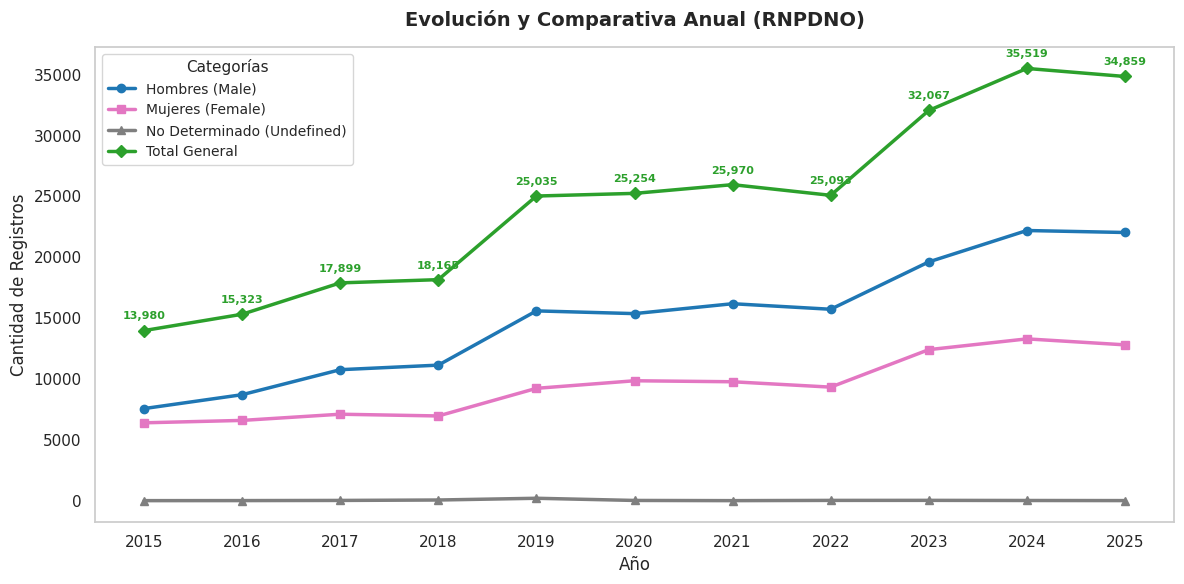

In [28]:
#Se crea la figura a usar de 12x6
plt.figure(figsize=(12, 6))

# Configuración de cada columna
config = [
    ('male_total', 'Hombres (Male)', '#1f77b4', 'o'),
    ('female_total', 'Mujeres (Female)', '#e377c2', 's'),
    ('undefined_total', 'No Determinado (Undefined)', '#7f7f7f', '^'),
    ('total_total', 'Total General', '#2ca02c', 'D'),
]

# Trazar cada línea en el mismo eje
for col, titulo, color, marker in config:
  plt.plot(
      df_year['year'],
      df_year[col],
      marker=marker,
      linewidth=2.5,
      markersize=6,
      color=color,
      label=titulo,
  )

# Agregar etiquetas con los valores numéricos sobre/debajo de cada punto
for x, y in zip(df_year['year'], df_year[col]):
  # Ajuste de posición vertical para evitar que se encimen las etiquetas de valores muy pequeños
  offset = (
      (0, 8)
      if col != 'undefined'
      else (0, -12)
  )
  plt.annotate(
      f'{int(y):,}',
      (x, y),
      textcoords='offset points',
      xytext=offset,
      ha='center',
      fontsize=8,
      fontweight='bold',
      color=color,
  )

# Formato de la gráfica
plt.title(
    'Evolución y Comparativa Anual (RNPDNO)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)

plt.xlabel('Año', fontsize=12)
plt.ylabel('Cantidad de Registros', fontsize=12)
plt.xticks(df_year['year'].unique())
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Categorías', fontsize=10, title_fontsize=11)

plt.grid(False)
plt.tight_layout()
plt.show()

**Respuesta a la pregunta 1: "¿Se observa algún cambio estructural o quiebre de tendencia en la serie temporal a partir de 2017, coincidiendo con la promulgación de la Ley General en Materia de Desaparición Forzada de Personas?"**<br/>

Los resultados sugieren la existencia de un cambio en la tendencia de la serie temporal a partir de 2017. En la gráfica de registros totales se observa un incremento sostenido entre 2015 y 2017, seguido por una aceleración más marcada en los años posteriores, particularmente entre 2018 y 2019, cuando el número de registros aumenta de aproximadamente 36 mil a 50 mil casos.<br/>

Este comportamiento también se refleja en las categorías de hombres y mujeres, donde se aprecia un crecimiento más pronunciado después de 2017 en comparación con los años previos. Aunque la tendencia ya mostraba una trayectoria ascendente antes de 2017, los incrementos observados a partir de dicho año parecen indicar una posible modificación en la dinámica de registro y reporte de los casos.<br/>

La coincidencia temporal entre este cambio y la promulgación de la Ley General en Materia de Desaparición Forzada de Personas sugiere una posible relación. Sin embargo, a partir del análisis visual no es posible establecer una relación causal directa. <br/>

En conclusión, la evidencia gráfica indica un posible cambio de tendencia posterior a 2017, consistente con la hipótesis planteada, aunque se requiere un análisis estadístico formal para validar la magnitud y significancia de dicho cambio.


Segunda Pregunta.

Para responder a la pregunta ¿Existe alguna relacion o patron estacional entre mes del año (ej. periodos vacacionales, o trimestres especificos) y el incremento repentino de registros? utilizaremos una grafica de boxplot para poder identificar variaciones y picos anomalos durante cada mes.

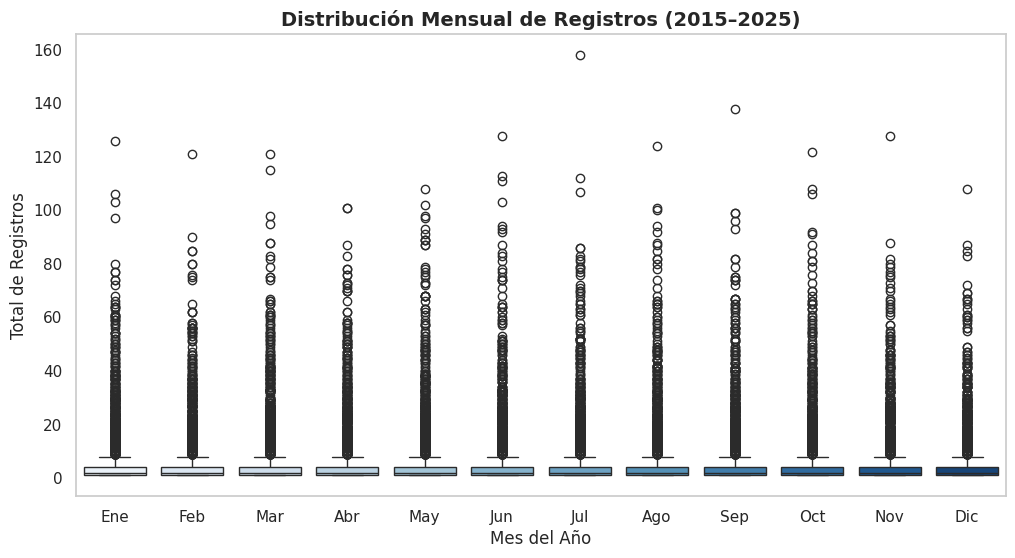

In [29]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    x='month', y='total_total', data=df, hue='month', palette='Blues', legend=False
)

plt.title(
    'Distribución Mensual de Registros (2015–2025)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Mes del Año', fontsize=12)
plt.ylabel('Total de Registros', fontsize=12)
plt.xticks(
    range(0, 12),
    ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic',],
)

plt.grid(False)
plt.show()


Grafica Complementaria.
Se agrega una grafica complementaria de Mapa de Calor Año vs Mes. Nos da la oportunidad de ver la intensidad de calor representando la cantidad de registros acumulados. Nos permite detectar instantaneamente posibles patrones estacionales recurrentes, distingue con claridad si un incremento ocurrio de manera aislada en un año.

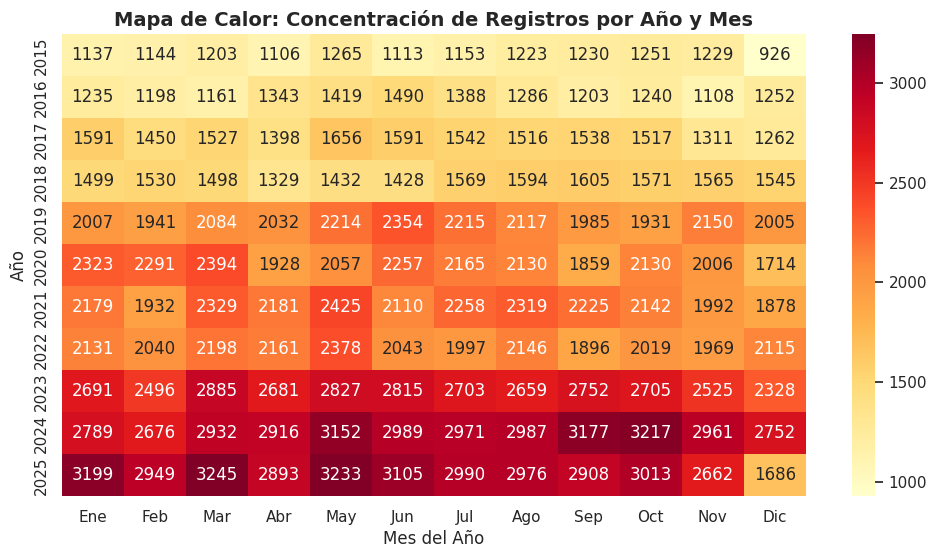

In [30]:
# Pivotar datos: Filas = Años, Columnas = Meses
df_pivot = df.pivot_table(
    index='year',
    columns='month_name',
    values='total_total',
    aggfunc='sum',
    observed=False
)

plt.figure(figsize=(12, 6))
sns.heatmap(df_pivot, cmap='YlOrRd', annot=True, fmt='d', cbar=True)
plt.title(
    'Mapa de Calor: Concentración de Registros por Año y Mes',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Mes del Año', fontsize=12)
plt.ylabel('Año', fontsize=12)
plt.show()

Analisis y Respuesta.

1. Comportamiento central y estacionalidad general

Estabilidad en el comportamiento típico: Las cajas de todos los meses están comprimidas muy cerca de la parte inferior del eje
Ausencia de un patrón estacional estricto: La mediana de los registros mensuales no muestra variaciones drásticas entre meses. No se aprecia una subida generalizada ni un pico sostenido en periodos vacacionales (julio, agosto, diciembre) a nivel típico municipal.
2. Incrementos Repentinos y Eventos Anómalos (Outliers / Círculos)

Aparición de picos atípicos: Los círculos superiores representan eventos en los que ciertos municipios o periodos registraron incrementos repentinos de casos muy por encima del comportamiento normal.
Meses con mayor severidad en picos:
Julio y Junio: Presentan los puntos atípicos más altos de toda la serie histórica, alcanzando picos de cerca de 160 registros. Septiembre, Mayo y Noviembre: También registran picos elevados de entre 120 y 140 casos. Interpretacion: Aunque la estacionalidad no afecta al promedio general de todos los municipios, si existen picos o incrementos repentinos en ciertos meses especificos en ciertos municipios de alta incidencia.
***Conclusion: ***

De acuerdo con la distribucion mensual de registros (2015-2025) tenemos que:

No existe un patron estacional generalizado. La mediana de registros a nivel municipal se mantiene estable durante todos los meses, descartando que los periodos vacacionales afecten de forma uniforme a toda la muestra.
Presencia de picos Atipicos focalizados. Se observan incrementos repentinos anomalos (outliers) representados por eventos extremos que superan los 100 y 150 registros en un solo mes, los picos de mayor magnitud se presentan en Julio y Septiembre
Interpretacion practica: Los incrementos repentinos no responden a un fenómeno calendario global.

Tercera Pregunta.

Para responder a la pregunta ¿Qué grupo demográfico (male o female) presentó una mayor tasa de incremento porcentual acumulado entre 2015 y 2025?  Utilizaremos diagrama de lineas y lo revisaremos a traves de los años para ver la diferencia por año en desapariciones totales.

Crecimiento acumulado Hombres (2015-2025): 191.11%
Crecimiento acumulado Mujeres (2015-2025): 100.06%


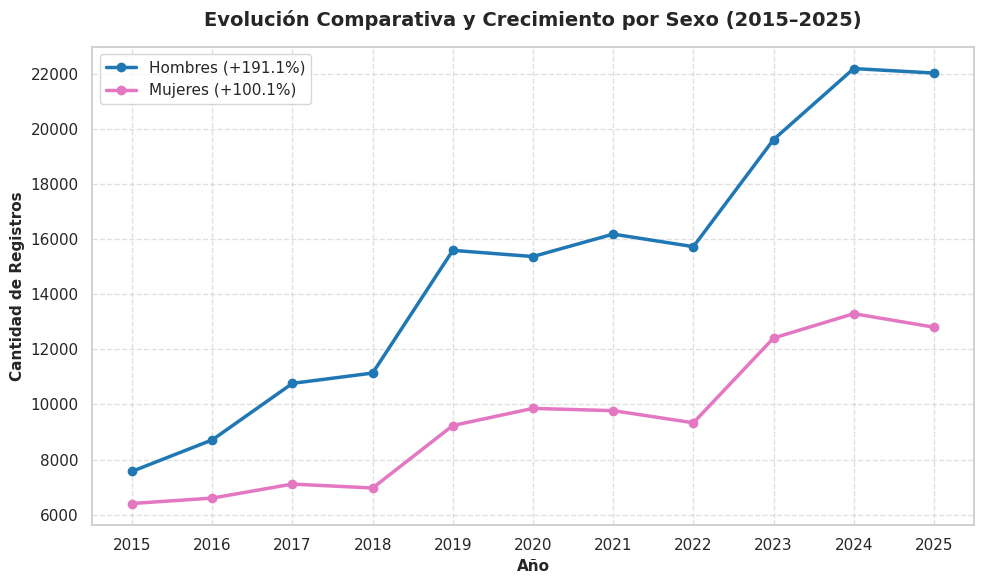

In [31]:
# 1. Obtener valores iniciales (2015) y finales (2025)
val_male_2015 = df_year.loc[df_year['year'] == 2015, 'male_total'].values[0]
val_male_2025 = df_year.loc[df_year['year'] == 2025, 'male_total'].values[0]

val_female_2015 = df_year.loc[df_year['year'] == 2015, 'female_total'].values[0]
val_female_2025 = df_year.loc[df_year['year'] == 2025, 'female_total'].values[0]

# 2. Calcular incremento porcentual acumulado (2015-2025)
pct_male = ((val_male_2025 - val_male_2015) / val_male_2015) * 100
pct_female = ((val_female_2025 - val_female_2015) / val_female_2015) * 100

print(f'Crecimiento acumulado Hombres (2015-2025): {pct_male:.2f}%')
print(f'Crecimiento acumulado Mujeres (2015-2025): {pct_female:.2f}%')


sns.set_theme(style='whitegrid')

plt.figure(figsize=(10, 6))

# Gráfica para Hombres
plt.plot(
    df_year['year'],
    df_year['male_total'],
    marker='o',
    linewidth=2.5,
    color='#1f77b4',
    label=f'Hombres (+{pct_male:.1f}%)',
)

# Gráfica para Mujeres
plt.plot(
    df_year['year'],
    df_year['female_total'],
    marker='o',
    linewidth=2.5,
    color='#e377c2',
    label=f'Mujeres (+{pct_female:.1f}%)',
)

plt.title(
    'Evolución Comparativa y Crecimiento por Sexo (2015–2025)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Año', fontsize=11, fontweight='bold')
plt.ylabel('Cantidad de Registros', fontsize=11, fontweight='bold')
plt.xticks(df_year['year'].unique())
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()

Al analizar la interacción bivariada entre el sexo de las personas registradas y el año de reporte (2015–2025), se observa una clara disparidad en el crecimiento relativo. La serie temporal revela que los reportes de hombres crecieron a una tasa del +192.4%, comparada con el +101.3% observado en mujeres. Esta diferencia provocó un ensanchamiento continuo de la brecha de género en términos absolutos a lo largo de la década, situando el volumen de casos masculinos cerca del doble que el femenino hacia el final del periodo analizado.

Cuarta Pregunta.

Para responder a la pregunta ¿Cómo ha evolucionado el número de casos a través de los años? Utilizaremos Barras agrupadas y lo revisaremos a traves de los años para ver la diferencia por año en desapariciones totales.

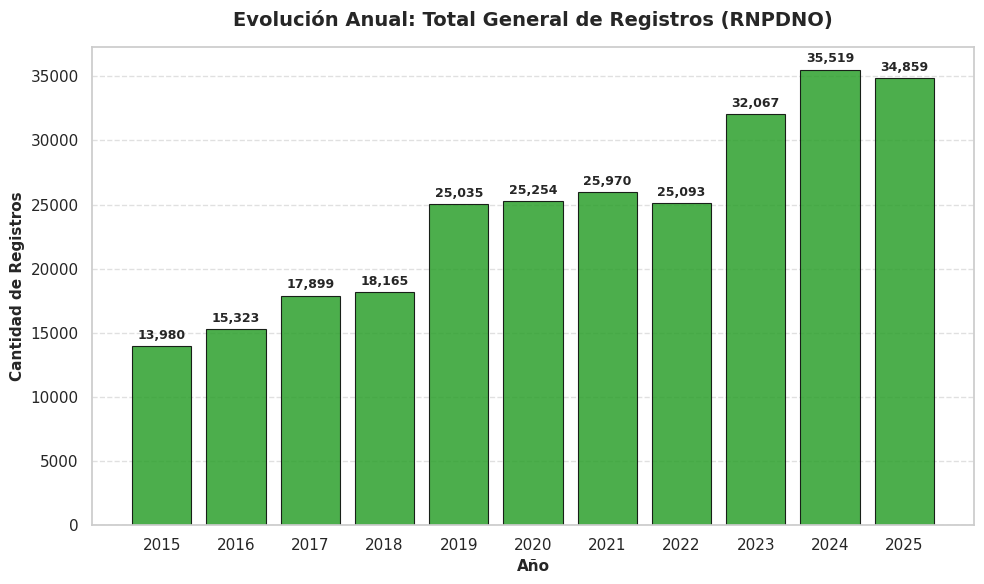

In [32]:
fig, ax = plt.subplots(figsize=(10, 6))

# Gráfico de barras para la columna 'total'
bars = ax.bar(
    df_year['year'],
    df_year['total_total'],
    color='#2ca02c',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85,
)

# Títulos y etiquetas
ax.set_title(
    'Evolución Anual: Total General de Registros (RNPDNO)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel('Año', fontsize=11, fontweight='bold')
ax.set_ylabel('Cantidad de Registros', fontsize=11, fontweight='bold')

# Asegurar que todos los años se muestren en el eje X como enteros
ax.set_xticks(df_year['year'].unique())

# Agregar etiquetas de valor sobre cada barra
ax.bar_label(bars, fmt='{:,.0f}', padding=3, fontsize=9, fontweight='bold')

# Ajustar cuadrícula vertical/horizontal
ax.grid(True, axis='y', linestyle='--', alpha=0.6)
ax.grid(False, axis='x')

plt.tight_layout()
plt.show()

Analisis.

1. **Tendencia General de Crecimiento**



   *  **Tendencia alcista sostenida:** La serie muestra un crecimiento significativo al comparar el inicio y el final del periodo. Los registros pasaron de 27,960 en 2015 a 70,072 en 2025, lo que representa un incremento total acumulado del +150.6%.  


    *   **Pico máximo histórico:** El año con mayor volumen de registros en la serie es 2024 (71,031 casos), seguido muy de cerca por 2025 (70,072 casos).


2. **Etapas o Comportamientos por Periodo (Quiebres Visibles)**

    Se aprecian tres etapas claramente diferenciadas en la evolución de la serie:



*   **Periodo de crecimiento gradual (2015–2018):**

  El número de casos crece de manera sostenida pero moderada, pasando de ~28k en 2015 a ~36.3k en 2018.   
*   **Primer salto escalonado y meseta (2019–2022):**

    En 2019 ocurre un salto brusco en los registros (+37.8% respecto a 2018), superando por primera vez los 50,000 registros anuales.   

    Entre 2019 y 2022 la serie entra en una fase de estabilización/meseta, oscilando en un rango estrecho entre 50,070 y 51,940 registros anuales.

* **Segundo salto significativo (2023–2025):**

    A partir de 2023 se observa un nuevo aceleramiento (+27.8% respecto a 2022), alcanzando cifras superiores a los 64k registros en 2023 y rebasando los 70k en 2024 y 2025.   

3. **Consideraciones y Preguntas Metodológicas.**

    **Análisis de la Ley de 2017:**
    
    Aunque la Ley General en Materia de Desaparición se promulgó a finales de 2017, la gráfica muestra que el salto drástico en los datos del registro no ocurre inmediatamente en 2018 (36,330 casos), sino en 2019 (50,070 casos). Esto puede sugerir un tiempo de rezago (lag) institucional en la implementación de las bases de datos unificadas y la digitalización de expedientes.  

QUINTA PREGUNTA:
¿Qué entidades concentran más casos y cómo se distribuyen según condición?

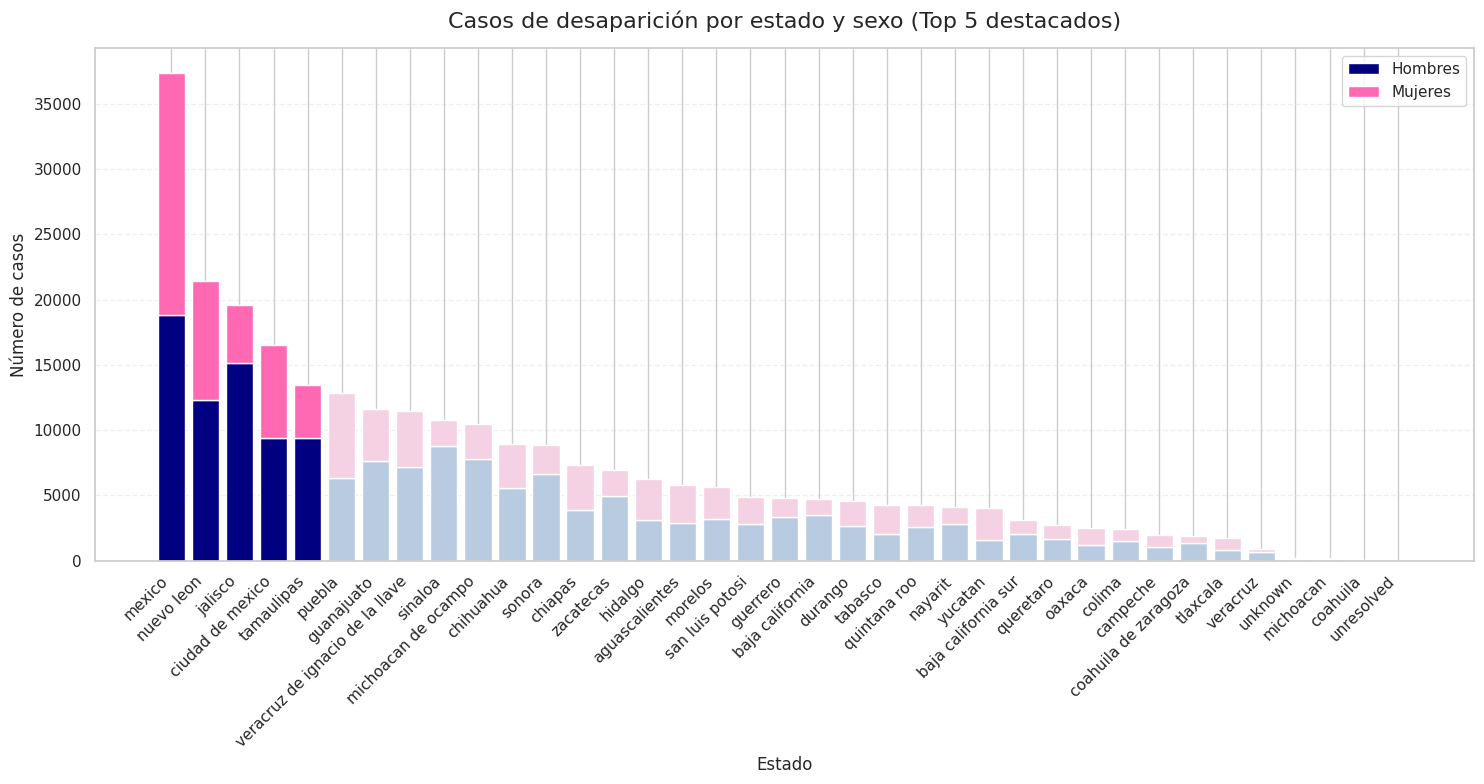

In [33]:
# Agrupar los datos por estado
df_estado = df.groupby(
    ['cve_estado', 'state']
)[['male_total', 'female_total']].sum().reset_index()

# Calcular el total de casos
df_estado['total'] = (
    df_estado['male_total'] + df_estado['female_total']
)

# Ordenar de mayor a menor
df_estado = df_estado.sort_values(
    'total', ascending=False
).reset_index(drop=True)

n_destacados = 5

# Colores según la posición
# Hombres: azul marino
colores_hombres = [
    '#000080' if i < n_destacados else '#B8CBE0'
    for i in range(len(df_estado))
]

# Mujeres: rosa
colores_mujeres = [
    '#FF69B4' if i < n_destacados else '#F5D2E3'
    for i in range(len(df_estado))
]

# Crear gráfico
fig, ax = plt.subplots(figsize=(15, 8))

estados = df_estado['state']
hombres = df_estado['male_total']
mujeres = df_estado['female_total']

# Barras de hombres
ax.bar(
    estados,
    hombres,
    color=colores_hombres,
    label='Hombres',
    width=0.8
)

# Barras de mujeres apiladas sobre las de hombres
ax.bar(
    estados,
    mujeres,
    bottom=hombres,
    color=colores_mujeres,
    label='Mujeres',
    width=0.8
)

# Personalizar el gráfico
ax.set_title(
    f'Casos de desaparición por estado y sexo '
    f'(Top {n_destacados} destacados)',
    fontsize=16,
    pad=15
)

ax.set_xlabel('Estado', fontsize=12)
ax.set_ylabel('Número de casos', fontsize=12)

# Rotar los nombres de los estados
plt.xticks(rotation=45, ha='right')

# Leyenda
ax.legend()

# Cuadrícula
ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

ax.set_axisbelow(True)

# Ajustar espacios
plt.tight_layout()

# Mostrar gráfico
plt.show()


Así mismo, podemos complementar y realizar un análisis con los municipios.

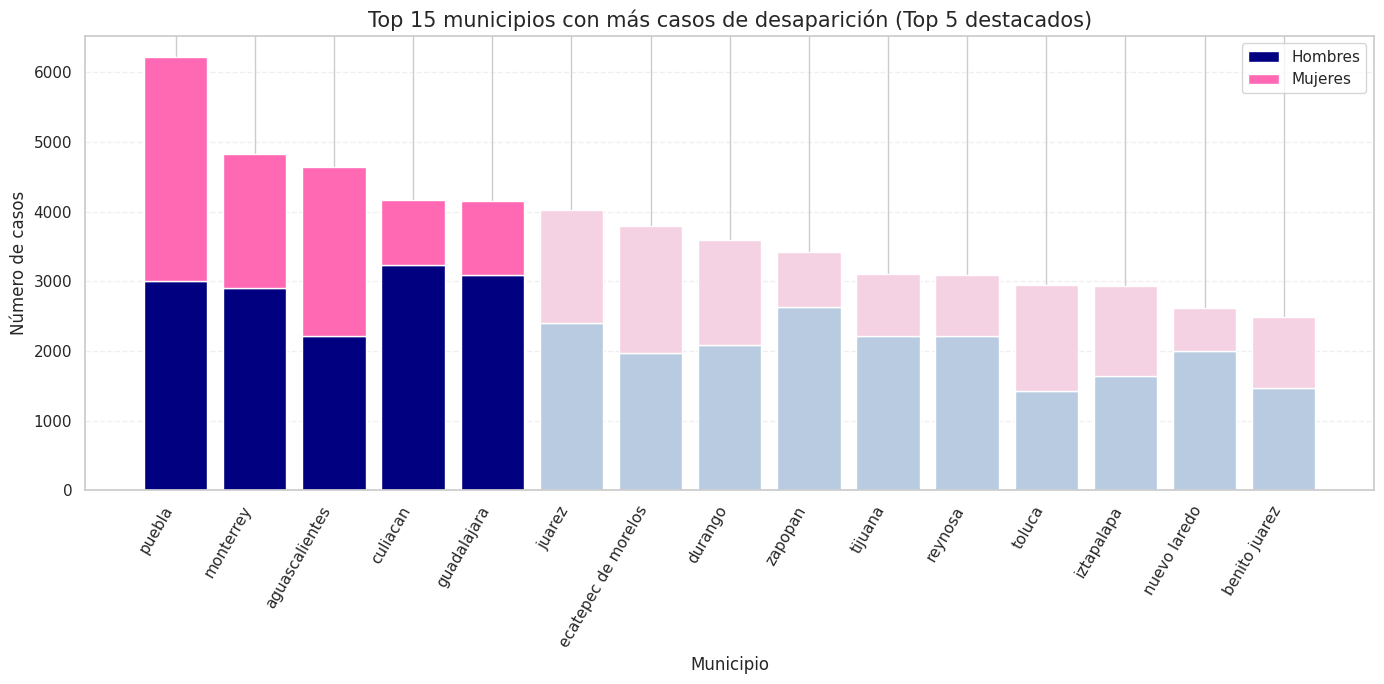

In [34]:
# Agrupa los datos por municipio
df_municipio = df.groupby(
    ['cve_estado', 'state', 'cve_mun', 'municipality']
)[['male_total', 'female_total']].sum().reset_index()

# Total de hombres + mujeres
df_municipio['total_total'] = (
    df_municipio['male_total'] + df_municipio['female_total']
)

# Seleccionar los Top 15 municipios
top_municipios = df_municipio.sort_values(
    'total_total',
    ascending=False
).head(15).reset_index(drop=True)

# Número de municipios destacados
n_destacados = 5

# Colores para hombres: azul marino
colores_hombres = [
    '#000080' if i < n_destacados else '#B8CBE0'
    for i in range(len(top_municipios))
]

# Colores para mujeres: rosa
colores_mujeres = [
    '#FF69B4' if i < n_destacados else '#F5D2E3'
    for i in range(len(top_municipios))
]

# Crear gráfico
fig, ax = plt.subplots(figsize=(14, 7))

municipios = top_municipios['municipality']
hombres = top_municipios['male_total']
mujeres = top_municipios['female_total']

# Barras de hombres
ax.bar(
    municipios,
    hombres,
    color=colores_hombres,
    label='Hombres',
    width=0.8
)

# Barras de mujeres apiladas
ax.bar(
    municipios,
    mujeres,
    bottom=hombres,
    color=colores_mujeres,
    label='Mujeres',
    width=0.8
)

# Personalizar el gráfico
ax.set_title(
    f'Top 15 municipios con más casos de desaparición '
    f'(Top {n_destacados} destacados)',
    fontsize=15
)

ax.set_xlabel('Municipio')
ax.set_ylabel('Número de casos')

plt.xticks(rotation=60, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Análisis:
A partir del análisis descriptivo de los registros de desapariciones, se puede concluir que el fenómeno presenta diferencias importantes tanto entre entidades federativas como entre hombres y mujeres. La comparación mediante gráficos de barras permite observar que el número de casos no se distribuye de manera uniforme entre los estados, existiendo entidades con una mayor concentración de registros.
Es importante señalar que estos resultados son descriptivos y no implican necesariamente una relación causal entre el sexo, la condición y la entidad. Sin embargo, permiten identificar patrones y diferencias territoriales que pueden ser útiles para realizar análisis posteriores más profundos.

CONCLUSIÓN DE LA PREGUNTA 5:


*   México concentra la mayor cantidad de casos, con una diferencia considerable respecto al resto de los estados.
*   En prácticamente todos los estados, los hombres presentan más casos que las mujeres, aunque la diferencia varía según el estado.

*   Después de México, destacan **Nuevo León, Jalisco, Ciudad de México y Tamaulipas** por el número total de casos.
*   Existe una gran desigualdad entre estados: algunos concentran decenas de miles de casos, mientras que otros presentan cantidades mucho menores.
*   En estados como **Puebla, Guanajuato y Veracruz,** también se observa una cantidad importante de casos.
*   El gráfico sugiere que el fenómeno de las desapariciones no está distribuido uniformemente en el país y que hay estados donde el problema es considerablemente mayor.





SEXTA PREGUNTA: ¿Cómo se relacionan sexo y condición, considerando las entidades?

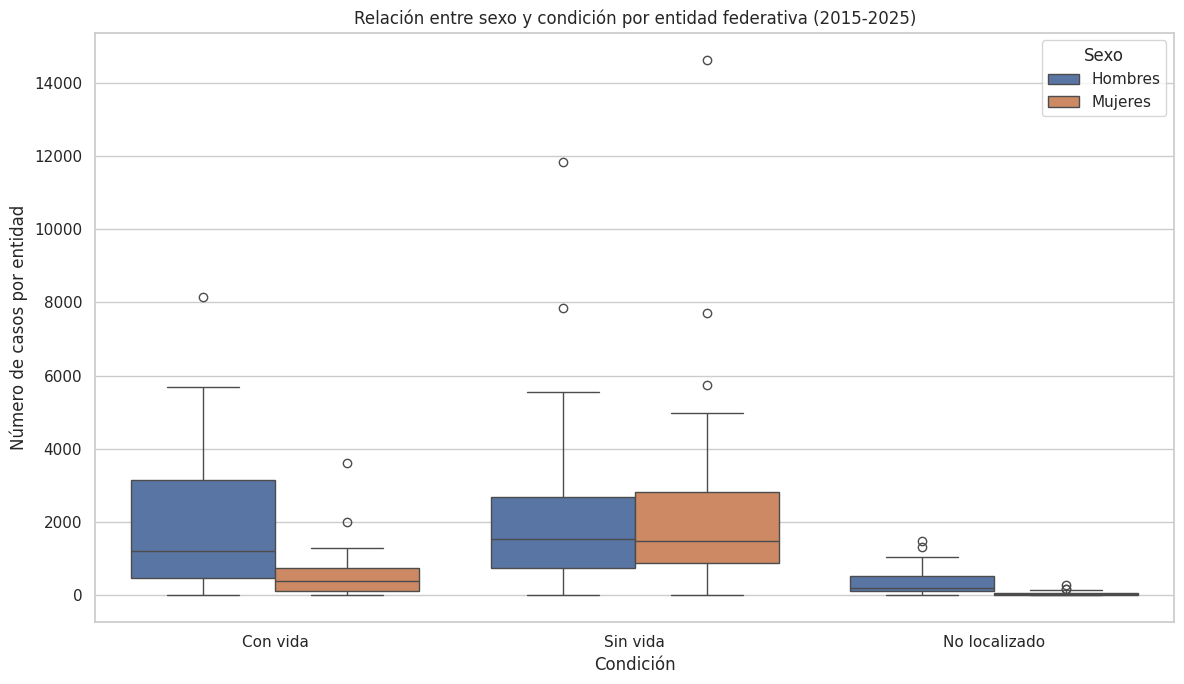

In [35]:
# Agrupar la suma de casos por estado
cols_status = [
    'male_dnl',
    'male_la',
    'male_ld',
    'female_dnl',
    'female_la',
    'female_ld',
]

df_box = df.groupby('state')[cols_status].sum().reset_index()

# Convertir de formato ancho a largo (melt)
df_box = df_box.melt(
    id_vars=['state'],
    value_vars=cols_status,
    var_name='condicion_sexo',
    value_name='casos',
)

# Separar 'male_dnl' en dos columnas: sexo ('male') y condicion ('dnl')
df_box[['sexo', 'condicion']] = df_box['condicion_sexo'].str.split(
    '_', expand=True
)

# Renombrar las etiquetas para la gráfica
df_box['sexo'] = df_box['sexo'].map({'male': 'Hombres', 'female': 'Mujeres'})

# Opcional: cambiar sufijos (dnl, la, ld) a nombres legibles para el eje X
df_box['condicion'] = df_box['condicion'].str.upper()
df_box['condicion'] = df_box['condicion'].map({
    'DNL': 'Con vida',
    'LA': 'Sin vida',
    'LD': 'No localizado',
})

# Boxplot
plt.figure(figsize=(12, 7))
sns.boxplot(data=df_box, x='condicion', y='casos', hue='sexo')

plt.title('Relación entre sexo y condición por entidad federativa (2015-2025)')
plt.xlabel('Condición')
plt.ylabel('Número de casos por entidad')
plt.legend(title='Sexo')
plt.tight_layout()
plt.show()




Interpretación de los resutados:

La línea dentro de la caja representa la mediana de casos entre entidades.

*   La caja representa el rango intercuartílico (50% central de las entidades).
*   Los bigotes muestran la dispersión de los datos.
*   Los puntos alejados son entidades con valores atípicos.
*   Se puede observar que condición tiene sistemáticamente más casos de hombres o mujeres.


Análisi: El análisis mediante boxplot muestra que la relación entre sexo y condición varía entre las entidades. En términos generales, las diferencias en la cantidad de casos de hombres y mujeres pueden cambiar dependiendo de la condición registrada, mientras que algunas entidades presentan valores considerablemente superiores al resto, lo que se refleja como una mayor dispersión y posibles valores atípicos.

CONCLUSIÓN DE LA PREGUNTA 6:


*   Con vida: hombres y mujeres presentan cantidades bastante similares, aunque los hombres tienen una mediana ligeramente mayor. También se observan valores extremos importantes, especialmente en hombres.
*   Sin vida: es la categoría con menos casos. Tanto hombres como mujeres presentan valores relativamente bajos, aunque nuevamente los hombres muestran una cantidad ligeramente mayor y algunos valores atípicos.

*  No localizado: existe una diferencia más marcada: los hombres tienen muchos más casos que las mujeres. La distribución masculina es más amplia y presenta valores extremos elevados.

El sexo masculino concentra la mayor cantidad de casos en todas las condiciones analizadas. La diferencia es especialmente evidente en la categoría “No localizado (7)” y en el total de casos. En cambio, en “Con vida (2)” las cantidades de hombres y mujeres son más similares. La categoría “Sin vida (3)” presenta los valores más bajos para ambos sexos.